# FEniCSx Laboratory · 01
## Poisson convergence and heat flow

Experiments for Chapter **1.2, Part I**, using actual DOLFINx assembly and PETSc solves.
This notebook is self-contained; no previous notebook or generated file is required.

[Chapter guide](README.md) · [Environment and outputs](NOTEBOOK_README.md) · [Part I exercises](exercises/FEniCSx_Part_I_Exercises.ipynb)

Use **DOLFINx 0.10.x**, a real float64 PETSc build, and a serial Python kernel.
Select **Restart Kernel and Run All Cells**. JIT compilation makes the first run
slower than later runs. Meshes are deliberately small, and Matplotlib replaces PyVista
so a desktop display is unnecessary. This notebook does not use legacy `fenics`.

The implementation follows the official [DOLFINx 0.10 solver API](https://docs.fenicsproject.org/dolfinx/v0.10.0/python/generated/dolfinx.fem.petsc.html).


In [1]:
import platform
import numpy as np
import scipy
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.linalg import eigh
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=4, suppress=True)
SEED = 7
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449"}
plt.rcParams.update({"figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.labelcolor": palette["ink"], "text.color": palette["ink"],
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
    "axes.titleweight": "bold", "grid.alpha": .35, "lines.linewidth": 2.2,
    "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "navy", "pink", "blue"]])})
print(f"Python {platform.python_version()} · NumPy {np.__version__} · SciPy {scipy.__version__}")
print("CPU / float64 / deterministic quadrature / seed", SEED)


Python 3.14.4 · NumPy 2.4.3 · SciPy 1.17.1
CPU / float64 / deterministic quadrature / seed 7


In [2]:
import itertools
from mpi4py import MPI
from petsc4py import PETSc
import dolfinx
from dolfinx import fem, mesh, default_scalar_type
from dolfinx.fem.petsc import LinearProblem, NonlinearProblem, assemble_matrix
import basix.ufl
import ufl
assert MPI.COMM_WORLD.size == 1, "Use a normal serial Jupyter kernel; plotting/CSR conversion here is serial."
assert np.dtype(PETSc.ScalarType) == np.dtype(np.float64), "Select a real-valued float64 PETSc environment."
assert dolfinx.__version__.startswith("0.10."), "These notebooks target DOLFINx 0.10.x; use the documented environment."
print("DOLFINx",dolfinx.__version__,"· PETSc",PETSc.Sys.getVersion())
print("MPI standard",MPI.Get_version(),"·",MPI.Get_library_version().splitlines()[0])
_prefixes=itertools.count()
def prefix(label): return f"notebook_{label}_{next(_prefixes)}_"
def integral(domain, expression):
    form=fem.form(expression*ufl.dx(domain=domain,metadata={"quadrature_degree":8}))
    return float(np.real(domain.comm.allreduce(fem.assemble_scalar(form),op=MPI.SUM)))
def boundary_dofs(V):
    domain=V.mesh; tdim=domain.topology.dim
    domain.topology.create_connectivity(tdim-1,tdim)
    facets=mesh.exterior_facet_indices(domain.topology)
    return fem.locate_dofs_topological(V,tdim-1,facets)
def zero_bc(V): return fem.dirichletbc(default_scalar_type(0.),boundary_dofs(V),V)
def linear_solve(a,L,bcs=(),label="linear"):
    problem=LinearProblem(a,L,bcs=list(bcs),petsc_options_prefix=prefix(label),
          petsc_options={"ksp_type":"preonly","pc_type":"lu","ksp_error_if_not_converged":True})
    solution=problem.solve();solution.x.scatter_forward()
    assert problem.solver.getConvergedReason()>0
    return solution


DOLFINx 0.10.0 · PETSc (3, 25, 0)
MPI standard (5, 0) · MPICH Version:      5.0.0


## 1 · The weak form becomes code

Solve $-\Delta u=2\pi^2\sin(\pi x)\sin(\pi y)$ on the unit square,
with zero boundary data. The exact solution is $u=\sin(\pi x)\sin(\pi y)$.
`TrialFunction`, `TestFunction`, `grad`, and `dx` represent
$\int\nabla u\cdot\nabla v=\int fv$ directly.

Boundary degrees of freedom are located topologically. The solver checks PETSc's
convergence status, and errors are integrated against the **analytical UFL expression**,
not its interpolant into the same finite element space.


In [3]:
def poisson_square(n=12,degree=1):
    domain=mesh.create_unit_square(MPI.COMM_WORLD,n,n)
    V=fem.functionspace(domain,("Lagrange",degree))
    x=ufl.SpatialCoordinate(domain)
    exact=ufl.sin(np.pi*x[0])*ufl.sin(np.pi*x[1])
    u,v=ufl.TrialFunction(V),ufl.TestFunction(V)
    uh=linear_solve(ufl.inner(ufl.grad(u),ufl.grad(v))*ufl.dx,
                    2*np.pi**2*exact*v*ufl.dx,[zero_bc(V)],"poisson")
    error=uh-exact
    errors=np.sqrt([integral(domain,error**2),integral(domain,ufl.inner(ufl.grad(error),ufl.grad(error)))])
    assert np.max(np.abs(uh.x.array[boundary_dofs(V)]))<1e-12
    return domain,V,uh,errors


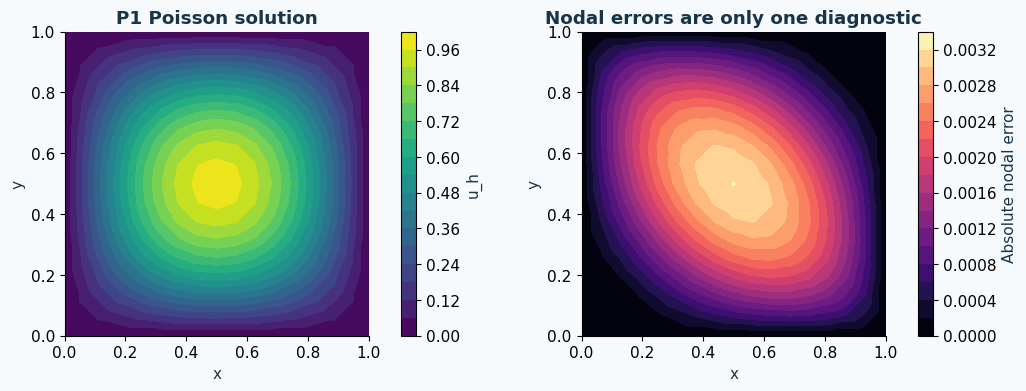

Integrated L2 / H1 seminorm errors: [0.0054 0.2175]


In [4]:
domain,V,uh,errors=poisson_square(n=16,degree=1)
xy=V.tabulate_dof_coordinates()[:,:2]
fig,axs=plt.subplots(1,2,figsize=(10.5,3.8),layout="constrained")
plot=axs[0].tricontourf(xy[:,0],xy[:,1],uh.x.array.real,levels=18,cmap="viridis")
fig.colorbar(plot,ax=axs[0],label="u_h")
axs[0].set(xlabel="x",ylabel="y",title="P1 Poisson solution",aspect="equal")
nodal_exact=np.sin(np.pi*xy[:,0])*np.sin(np.pi*xy[:,1])
plot=axs[1].tricontourf(xy[:,0],xy[:,1],np.abs(uh.x.array.real-nodal_exact),levels=18,cmap="magma")
fig.colorbar(plot,ax=axs[1],label="Absolute nodal error")
axs[1].set(xlabel="x",ylabel="y",title="Nodal errors are only one diagnostic",aspect="equal")
plt.show()
print("Integrated L2 / H1 seminorm errors:",errors)


## 2 · Change the space, keep the PDE fixed

Compare P1 and P2 spaces on three meshes. For this smooth problem, the expected
orders are $p+1$ in $L^2$ and $p$ in the $H^1$ seminorm. The plot uses $1/N$
as the mesh scale; the largest triangle diameter is $\sqrt2/N$, which changes the
constant but not the slope. Independent quadrature of degree 8 resolves the errors.


P1 last rates [L2, H1 seminorm]: [1.9745 0.9891]


P2 last rates [L2, H1 seminorm]: [2.9951 1.9875]


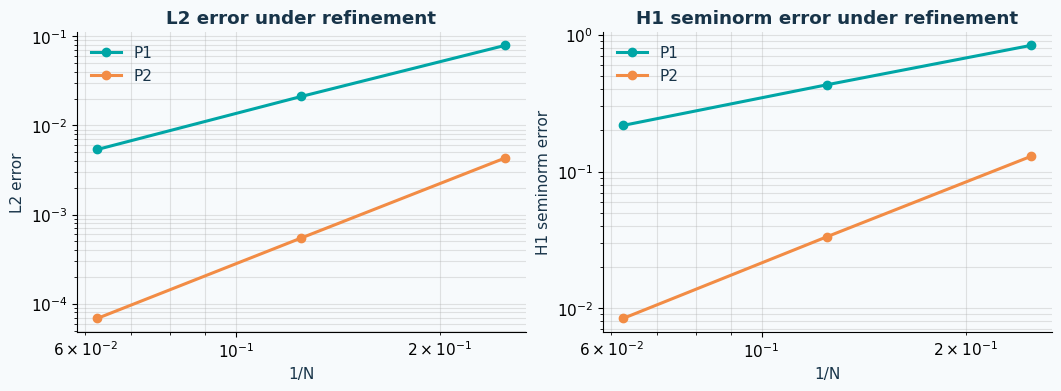

In [5]:
records={}
fig,axs=plt.subplots(1,2,figsize=(10.5,3.8),layout="constrained")
for degree in [1,2]:
    rows=[]
    for n in [4,8,16]:
        _,_,_,err=poisson_square(n,degree);rows.append((1/n,*err))
    rows=np.array(rows);records[degree]=rows
    rates=np.log2(rows[:-1,1:]/rows[1:,1:])
    print(f"P{degree} last rates [L2, H1 seminorm]:",rates[-1])
    assert abs(rates[-1,0]-(degree+1)) < .2 and abs(rates[-1,1]-degree)<.2
    for j in range(2): axs[j].loglog(rows[:,0],rows[:,j+1],"o-",label=f"P{degree}")
for ax,label in zip(axs,["L2 error","H1 seminorm error"]):
    ax.set(xlabel="1/N",ylabel=label,title=label+" under refinement");ax.legend();ax.grid(which="both")
plt.show()


## 3 · Backward Euler and Crank–Nicolson

On $(0,1)$, $u_t-u_{xx}=0$ with $u(0,x)=\sin(\pi x)$ has the exact solution
$e^{-\pi^2t}\sin(\pi x)$. Each step assembles the theta-method weak form.
The previous state is a `Function`; copying new coefficient values and updating
its ghost values makes the next right-hand side use the correct time level.

Compare the finite element energy $\tfrac12\int u_h^2$ and the final error.
These errors contain both spatial and temporal contributions.


In [6]:
def heat_interval(n=40,dt=.002,final_time=.04,theta=1.):
    domain=mesh.create_unit_interval(MPI.COMM_WORLD,n)
    V=fem.functionspace(domain,("Lagrange",1))
    old=fem.Function(V);old.interpolate(lambda x:np.sin(np.pi*x[0]))
    old.x.scatter_forward()
    steps=max(1,int(np.ceil(final_time/dt)));dt=final_time/steps
    u,v=ufl.TrialFunction(V),ufl.TestFunction(V)
    a=(u*v+theta*dt*ufl.inner(ufl.grad(u),ufl.grad(v)))*ufl.dx
    L=(old*v-(1-theta)*dt*ufl.inner(ufl.grad(old),ufl.grad(v)))*ufl.dx
    problem=LinearProblem(a,L,bcs=[zero_bc(V)],petsc_options_prefix=prefix("heat"),
             petsc_options={"ksp_type":"preonly","pc_type":"lu","ksp_error_if_not_converged":True})
    energies=[.5*integral(domain,old**2)]
    for _ in range(steps):
        new=problem.solve()
        old.x.array[:]=new.x.array;old.x.scatter_forward()
        energies.append(.5*integral(domain,old**2))
    x=ufl.SpatialCoordinate(domain)
    exact=np.exp(-np.pi**2*final_time)*ufl.sin(np.pi*x[0])
    error=np.sqrt(integral(domain,(old-exact)**2))
    coords=V.tabulate_dof_coordinates()[:,0];order=np.argsort(coords)
    return coords[order],old.x.array.real[order].copy(),np.linspace(0,final_time,steps+1),np.array(energies),error


Backward Euler: final integrated L2 error = 3.29325e-03


Crank–Nicolson: final integrated L2 error = 3.82020e-04


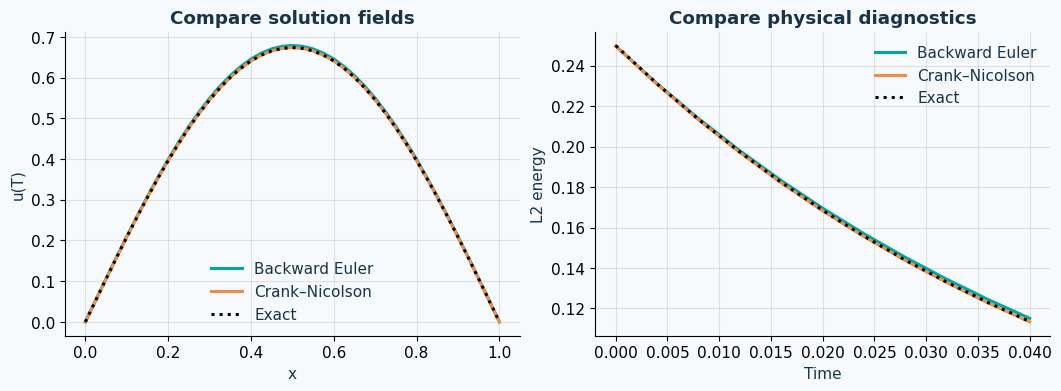

In [7]:
fig,axs=plt.subplots(1,2,figsize=(10.5,3.8),layout="constrained")
for theta,label in [(1.,"Backward Euler"),(.5,"Crank–Nicolson")]:
    x,values,t,E,error=heat_interval(theta=theta,dt=.004)
    assert np.max(np.diff(E)) < 1e-11
    axs[0].plot(x,values,label=label);axs[1].plot(t,E,label=label)
    print(f"{label}: final integrated L2 error = {error:.5e}")
axs[0].plot(x,np.exp(-np.pi**2*t[-1])*np.sin(np.pi*x),"k:",label="Exact")
axs[1].plot(t,.25*np.exp(-2*np.pi**2*t),"k:",label="Exact")
axs[0].set(xlabel="x",ylabel="u(T)",title="Compare solution fields")
axs[1].set(xlabel="Time",ylabel="L2 energy",title="Compare physical diagnostics")
for ax in axs: ax.legend();ax.grid()
plt.show()


## Try next

Use P2 heat elements, halve the time step, and explain which error dominates.
Add a nonzero forcing manufactured from a chosen time-dependent solution.
Replace homogeneous Dirichlet data by a Neumann condition and derive the boundary
term before editing the code. Record both solver convergence and a PDE-level error;
one does not replace the other.
